In [1]:
import pandas as pd
import numpy as np
import random
import tensorflow as tf

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import PassiveAggressiveClassifier

from sklearn.utils import shuffle
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
import joblib

from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense, Concatenate
from tensorflow.keras.utils import to_categorical

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# import os
# os.environ['TF_CPP_MIN_LOG_LEVEL'] = ''


Dataset Link: https://www.kaggle.com/datasets/01a9c71a93d56cf3beec9a5436c7d02ef66df3259fdb483a4864b803ea3ced6b


# Robust Text Classification: SMS Spam Collection, Spam and Ham Classification, SpamAssassin

**Spam-mails Dataset**

In [2]:


pd.set_option('display.max_colwidth', 300)

# NEWS Dataset CSV file path
df_mail = pd.read_csv('/kaggle/input/datasets/shafiqulbashar/spam-mails-dataset/spam_ham_dataset.csv')


# Check structure
df_mail.head()

,Unnamed: 0,label,text,label_num
0,605,ham,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,2030,ham,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


In [3]:


# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_mail['label'].value_counts(),
    'Percentage': (df_mail['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
ham     3672       71.01
spam    1499       28.99


In [4]:

#Dropping columns that are not needed
df_mail = df_mail.drop('Unnamed: 0', axis=1)
df_mail = df_mail.drop('label', axis=1)

# rename label_num
df_mail.rename(columns={'label_num': 'label'}, inplace=True)

# Check structure
df_mail.head()

,text,label
0,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


**SMS-spam-collection-dataset**

In [5]:

# Replace with your actual CSV file path
df_sms = pd.read_csv('/kaggle/input/datasets/shafiqulbashar/sms-spam-collection-dataset/spam.csv',
                 encoding="latin-1", encoding_errors="replace")


# Check structure
df_sms.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


In [6]:

#Dropping columns that are not needed
df_sms = df_sms.drop('Unnamed: 2', axis=1)
df_sms = df_sms.drop('Unnamed: 3', axis=1)
df_sms = df_sms.drop('Unnamed: 4', axis=1)

# rename label_num
df_sms.rename(columns={'v1': 'label'}, inplace=True)
df_sms.rename(columns={'v2': 'text'}, inplace=True)

# Check structure
df_sms.head()


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [7]:

# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_sms['label'].value_counts(),
    'Percentage': (df_sms['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
ham     4825       86.59
spam     747       13.41


In [9]:

#Swapping the dataframe columns 
df_sms = df_sms[['text', 'label']]

if df_sms['label'].dtype == object:
    df_sms['label'] = df_sms['label'].str.upper().map({'HAM': 0, 'SPAM': 1})

df_sms.head()

,text,label
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives around here though",0


**Spam and Ham Classification SpamAssassin**

In [10]:

# Replace with your actual CSV file path
df_spam = pd.read_csv('/kaggle/input/datasets/bayes2003/emails-for-spam-or-ham-classification-spamassassin/email_text.csv',
                 encoding="latin-1", encoding_errors="replace")


# Check structure
df_spam.head()

,label,text
0,0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...
1,0,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...
2,0,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...
3,0,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...
4,0,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...


In [11]:

# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_spam['label'].value_counts(),
    'Percentage': (df_spam['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
0       4072        72.2
1       1568        27.8


In [12]:


#Swapping the dataframe columns 
df_spam = df_spam[['text', 'label']]

# if df_spam['label'].dtype == object:
#     df_spam['label'] = df_spam['label'].str.upper().map({'HAM': 0, 'SPAM': 1})

df_spam.head()

,text,label
0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...,0
1,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...,0
2,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...,0
3,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...,0
4,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...,0


# **Pre-Processing**

# Combine Dataset

In [13]:
# Combining Dataset

# Add domain identifiers
# df_mail['domain'] = 'news'
# df_sms['domain'] = 'sms'
# df_spam['domain'] = 'email'
# df_health['domain'] = 'health'

# Assisgn Test
df_test = df_spam.copy() #df_mail

# Combine source domains
df_combine = pd.concat(
    [df_mail, df_sms, ], #  df_spam 
)

print("Combined source training data:")
print(df_combine.shape)

print("\nClass distribution:")
print(df_combine['label'].value_counts())

print("\nClass distribution (%):")
print((df_combine['label'].value_counts(normalize=True) * 100).round(2))

# print("\nDomain distribution:")
# print(df_combine['domain'].value_counts())


Combined source training data:
(10743, 2)

Class distribution:
label
0    8497
1    2246
Name: count, dtype: int64

Class distribution (%):
label
0    79.09
1    20.91
Name: proportion, dtype: float64


In [14]:
# Shuffle
df_combine = df_combine.sample(frac=1, random_state=42).reset_index(drop=True)

df_combine

,text,label
0,"\Happy valentines day\"" I know its early but i have hundreds of handsomes and beauties to wish. So i thought to finish off aunties and uncles 1st...""",0
1,"Subject: re : nom / alloc for june 6 th\r\nwe agree\r\n"" eileen ponton "" on 06 / 07 / 2001 10 : 21 : 35 am\r\nto : david avila / lsp / enserch / us @ tu , charlie stone / energy / txu @ tu , melissa\r\njones / energy / txu @ tu , teacton @ aep . com , szajac @ aep . com\r\ncc :\r\nsubject : nom ...",0
2,Subject: can you facilitate ?\r\npardon the abruptness and the liberty of this\r\nletter ; it is due to its exigency .\r\ni am a bank official in the uk . i write to ask for your help .\r\ni am in need of a foreign partner to assist in the transfer of a\r\nconsiderable amount of money .\r\nwhat ...,1
3,Oh you got many responsibilities.,0
4,Subject: re [ 3 ]\r\npaint shop small world ! could i speak to . . . in 1869 i ' ll call back ! surfing,1
...,...,...
10738,GENT! We are trying to contact you. Last weekends draw shows that you won a å£1000 prize GUARANTEED. Call 09064012160. Claim Code K52. Valid 12hrs only. 150ppm,1
10739,Is that seriously how you spell his name?,0
10740,Yeah you should. I think you can use your gt atm now to register. Not sure but if there's anyway i can help let me know. But when you do be sure you are ready.,0
10741,"Subject: re : meter 1459 , 6 / 00\r\nyep , you ' re right , except it ' s out there for june 1999 . please let me know .\r\ni ' ll be out tomorrow , if you get this done then , let carlos know and he can\r\nget it set up in pops .\r\naimee\r\ndaren j farmer\r\n07 / 13 / 2000 01 : 16 pm\r\nto : a...",0


In [15]:

df_test.head()

,text,label
0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...,0
1,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...,0
2,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...,0
3,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...,0
4,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...,0


In [16]:

print("TRAIN labels:")
print(df_combine['label'].value_counts())
print(df_combine['label'].value_counts(normalize=True))

print("\nTEST labels:")
print(df_test['label'].value_counts())
print(df_test['label'].value_counts(normalize=True))

print("\nUnique labels:")
print("Train:", df_combine['label'].unique())
print("Test :", df_test['label'].unique())

TRAIN labels:
label
0    8497
1    2246
Name: count, dtype: int64
label
0    0.790934
1    0.209066
Name: proportion, dtype: float64

TEST labels:
label
0    4072
1    1568
Name: count, dtype: int64
label
0    0.721986
1    0.278014
Name: proportion, dtype: float64

Unique labels:
Train: [0 1]
Test : [0 1]


# **Clean Text**

In [17]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [19]:
# Function creation for data cleanup, data manipulation and removal of stopwords
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import re

STOPWORDS = set(stopwords.words('english'))
STOPWORDS.remove('not') #removing not from the stop words
lemmatizer = WordNetLemmatizer()

# def clean_text(text):
#     text = text.lower() # lowercase text
#     text = ' '.join(word for word in text.split() if word not in STOPWORDS) # remove stopwords from text
#     # text = re.sub(r'\b(clinton|trump|hillary|obama|said)\b', '', text)

#     text = re.sub(r'\W', ' ', text) # Remove all the special characters
#     text = re.sub(r'\d+', '', text) # remove numerical values not for Health related DS
#     text = re.sub(r'<.*?>', '', text) # remove HTML tags
#     text = re.sub(r'http\S+', '', text) # remove URLs
#     text = re.sub(r'(?i)\bsubject\s*:?\s*', '', text)  # Remove "Subject" or "Subject:" (case-insensitive)
#     text = re.sub(r'\s+[a-zA-Z]\s+', ' ', text)  # remove all single characters
#     text = re.sub(r'\^[a-zA-Z]\s+', ' ', text) # Remove single characters from the start
#     text = re.sub(r'\s+', ' ', text, flags=re.I) # Substituting multiple spaces with single space
#     text = ' '.join(lemmatizer.lemmatize(word) for word in text.split()) # perform lemmatization to get the root of english words
#     return text

def clean_text(text):
    if not isinstance(text, str):
        text = str(text)

    text = text.lower()

    # Preserve useful structural information
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'\S+@\S+', ' EMAIL ', text)

    # HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Normalize whitespace only
    text = re.sub(r'\s+', ' ', text).strip()

    return text
    
# def clean_text(text):
#     if not isinstance(text, str):
#         text = str(text)

#     text = text.lower()
      
#     text = re.sub(r'<[^>]+>', ' ', text)                          # HTML first
#     text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)        # then URLs
#     text = re.sub(r'\S+@\S+', ' EMAIL ', text)                    # then emails
#     text = re.sub(r'^\s*subject\s*:?\s*', '', text)
#     text = re.sub(r'[£€¥$]', ' CURRENCY ', text)
#     text = re.sub(r'[^\x00-\x7F]+', ' ', text)  # now only catches true encoding artifacts
#     text = re.sub(r'escapenumber', ' NUM ', text, flags=re.IGNORECASE)
#     text = re.sub(r'\d+', ' NUM ', text)
#     text = re.sub(r'(NUM[\s/:\-,.]*)+', 'NUM ', text)
    
#     text = re.sub(r'\s+', ' ', text).strip()

#     return text

# def clean_text(text):
#     if not isinstance(text, str):
#         text = str(text)
        
#     # Convert to lowercase
#     text = text.lower()
    
#     # Replace URLs with a token
#     text = re.sub(r'http\S+|www\S+', ' URL ', text)
    
#     # Replace email addresses with a token
#     text = re.sub(r'\S+@\S+', ' EMAIL ', text)
    
#     # Remove HTML tags
#     text = re.sub(r'<.*?>', ' ', text)
    
#     # Optional: Normalize prolonged characters (e.g., "freeeeee" -> "free")
#     text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
#     # Clean up extra whitespace and trim
#     text = re.sub(r'\s+', ' ', text).strip()
    
#     return text

In [20]:
#Function testing
print(clean_text('Viral Dubai chocolate  craze!!! drives   pistachio costs \n up by Dh10 per kg in two months; Not Cheap(!)'))

viral dubai chocolate craze!!! drives pistachio costs up by dh10 per kg in two months; not cheap(!)


In [21]:

#Apply Text Cleaning to text---
df_combine['text'] = df_combine['text'].apply(clean_text)

df_combine['text'].count()

np.int64(10743)

In [22]:


#Apply Text Cleaning to Test---
df_test['text'] = df_test['text'].apply(clean_text)

df_test['text'].count()

np.int64(5640)

In [23]:

df_combine.head()

,text,label
0,"\happy valentines day\"" i know its early but i have hundreds of handsomes and beauties to wish. so i thought to finish off aunties and uncles 1st...""",0
1,"subject: re : nom / alloc for june 6 th we agree "" eileen ponton "" on 06 / 07 / 2001 10 : 21 : 35 am to : david avila / lsp / enserch / us @ tu , charlie stone / energy / txu @ tu , melissa jones / energy / txu @ tu , teacton @ aep . com , szajac @ aep . com cc : subject : nom / alloc for june 6...",0
2,subject: can you facilitate ? pardon the abruptness and the liberty of this letter ; it is due to its exigency . i am a bank official in the uk . i write to ask for your help . i am in need of a foreign partner to assist in the transfer of a considerable amount of money . what we require is some...,1
3,oh you got many responsibilities.,0
4,subject: re [ 3 ] paint shop small world ! could i speak to . . . in 1869 i ' ll call back ! surfing,1


In [24]:
df_test.head()

,text,label
0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...,0
1,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...,0
2,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...,0
3,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism and...,0
4,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...,0


# Exploratory Data Analysis

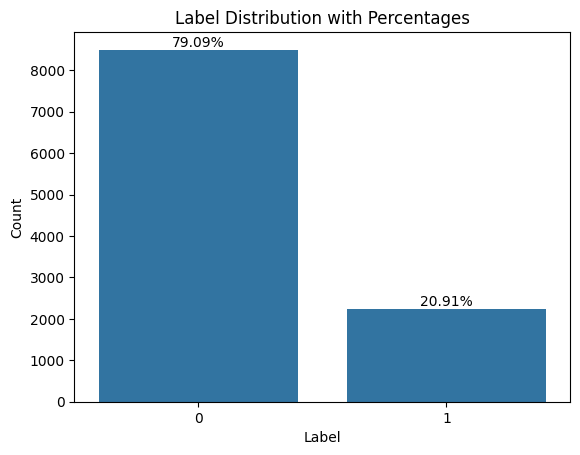

In [25]:

# Dataset Distribution

# Create count plot
ax = sns.countplot(x=df_combine.label)

# Get total number of samples
total = len(df_combine.label)

# Annotate percentages on bars
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

# Add title and labels
plt.title('Label Distribution with Percentages')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

In [26]:

# Word Count for news text

# Word Count
total_words = df_combine['text'].apply(lambda x: len(x.split())).sum()

# Character Count
total_characters = df_combine['text'].apply(len).sum()

# Sentence Count
total_sentences = df_combine['text'].apply(lambda x: len(sent_tokenize(x))).sum()

print(f"Word count for News: {total_words:,}")
print(f"Character count: {total_characters:,}")
print(f"Sentence count: {total_sentences:,}")

Word count for News: 1,264,199
Character count: 5,766,666
Sentence count: 78,494


**Word Map**

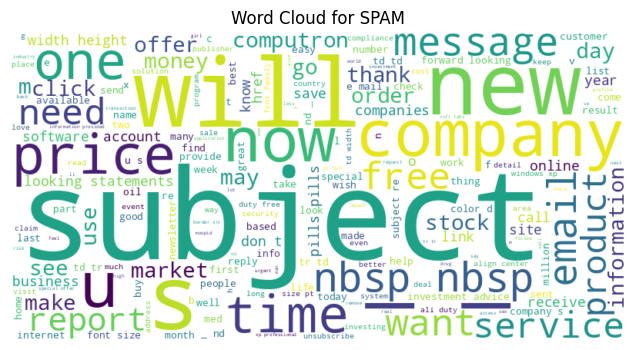

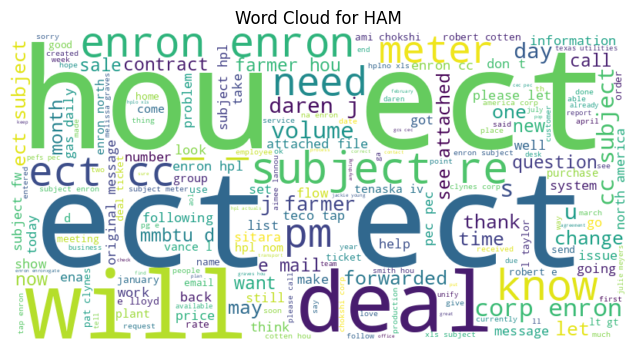

In [44]:

from wordcloud import WordCloud, STOPWORDS

stopwords = set(STOPWORDS)

# Create combined string for each class:  'FAKE': 1, 'REAL': 0
spam_text = " ".join(df_combine[df_combine['label'] == 1]['text'].tolist())
ham_text = " ".join(df_combine[df_combine['label'] == 0]['text'].tolist())

# Create WordClouds
fake_wc = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(spam_text)
real_wc = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(ham_text)

# Plot Fake News Word Cloud
plt.figure(figsize=(8,4))
plt.imshow(fake_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for SPAM")
plt.show()

# Plot Real News Word Cloud
plt.figure(figsize=(8, 4))
plt.imshow(real_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for HAM")
plt.show()

# **Parameterized Pipeline**

In [27]:

# Parametirized pipeline
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import optuna


# ============================================================
# 1. Select input features
# ============================================================

X_train = df_combine[['text']]
X_test = df_test[['text']]

y_train = df_combine[['label']]
y_test = df_test[['label']]


# Convert label DataFrames to 1D arrays
y_train = y_train.values.ravel()
y_test = y_test.values.ravel()


# ============================================================
# 2. Parameterized preprocessing pipeline
# ============================================================

def get_preprocessing_pipeline(
    max_features=None,
    vectorizer_type='tfidf',
    ngram_min=1,
    ngram_max=2,
    min_df=1
):

    # Select vectorizer
    if vectorizer_type == 'count':

        vectorizer = CountVectorizer(
            analyzer='char',
            max_features=max_features,
            ngram_range=(ngram_min, ngram_max),
            min_df=min_df,
            max_df=1.0
        )

    elif vectorizer_type == 'tfidf':

        vectorizer = TfidfVectorizer(
            analyzer='char',
            max_features=max_features,
            ngram_range=(ngram_min, ngram_max),
            min_df=min_df,
            max_df=1.0
        )

    else:
        raise ValueError(
            "vectorizer_type must be either 'count' or 'tfidf'"
        )

    # Pipeline
    pipeline = Pipeline([
        ('vectorizer', vectorizer)
    ])

    return pipeline

# **Logistic Regression**

In [80]:

## Hyper Parameter Tuning for Logistic regression
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. Logistic Regression hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-3,
        10.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    solver = trial.suggest_categorical(
        "solver",
        ["liblinear", "saga"]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_lr = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_lr.fit_transform(
        X_train['text']
    )

    X_test_transformed = pipeline_lr.transform(
        X_test['text']
    )


    # --------------------------------------------------------
    # 6. Logistic Regression model
    # --------------------------------------------------------

    model = LogisticRegression(
        C=C,
        penalty="l2",
        solver=solver,
        class_weight="balanced",
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-12 07:12:29,731] A new study created in memory with name: no-name-374a68b4-905c-403e-b8bc-827bfee172b5
[I 2026-09-12 07:12:29,735] Trial 0 pruned. 
[I 2026-09-12 07:14:49,469] Trial 1 finished with value: 0.5345744680851063 and parameters: {'C': 0.2593365420283326, 'max_iter': 476, 'solver': 'saga', 'vectorizer_type': 'count', 'max_features': 394479, 'ngram_min': 3, 'ngram_max': 5, 'min_df': 5}. Best is trial 1 with value: 0.5345744680851063.
[I 2026-09-12 07:15:23,146] Trial 2 finished with value: 0.5650709219858157 and parameters: {'C': 0.0032760281751790833, 'max_iter': 302, 'solver': 'saga', 'vectorizer_type': 'count', 'max_features': 448748, 'ngram_min': 4, 'ngram_max': 4, 'min_df': 2}. Best is trial 2 with value: 0.5650709219858157.
[I 2026-09-12 07:18:05,608] Trial 3 finished with value: 0.32588652482269503 and parameters: {'C': 0.001761231113569272, 'max_iter': 426, 'solver': 'saga', 'vectorizer_type': 'count', 'max_features': 390509, 'ngram_min': 1, 'ngram_max': 5, 


Best Trial:
Accuracy: 0.8656028368794326

Best Parameters:
  C: 0.011378270472360315
  max_iter: 270
  solver: liblinear
  vectorizer_type: count
  max_features: 380395
  ngram_min: 5
  ngram_max: 5
  min_df: 2


In [28]:

#Logistic Regression
# Best Optuna parameters
best_C = 0.011378270472360315
best_max_iter = 270
best_solver = "liblinear"
best_vectorizer_type = "count"
best_max_features = 380395
best_ngram_min = 5
best_ngram_max = 5
best_min_df = 2


# Parameterized character-level preprocessing pipeline
pipeline_lr = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# Transform text
X_train_transformed = pipeline_lr.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_lr.transform(
    X_test["text"]
)


# Final Logistic Regression model
modelLR = LogisticRegression(
    C=best_C,
    penalty="l2",
    solver=best_solver,
    class_weight="balanced",
    max_iter=best_max_iter,
    random_state=42
)


# Train
modelLR.fit(
    X_train_transformed,
    y_train
)


# Prediction
y_pred = modelLR.predict(
    X_test_transformed
)


# Evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Logistic Regression")
print("Accuracy:", accuracy)
print("Macro F1:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Logistic Regression
Accuracy: 0.8656028368794326
Macro F1: 0.8310703320412058

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.91      0.91      4072
           1       0.77      0.74      0.75      1568

    accuracy                           0.87      5640
   macro avg       0.83      0.83      0.83      5640
weighted avg       0.86      0.87      0.86      5640



# **Linear SVC**

In [29]:

## Hyper Parameter Tuning for LinearSVC

import optuna
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. LinearSVC hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-3,
        10.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    loss = trial.suggest_categorical(
        "loss",
        ["hinge", "squared_hinge"]
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        [None, "balanced"]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_svc = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_svc.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_svc.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # 6. LinearSVC model
    # --------------------------------------------------------

    model = LinearSVC(
        C=C,
        loss=loss,
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-12 14:20:56,043] A new study created in memory with name: no-name-ec3e331d-75c4-4531-a848-5e4a973e3b23
[I 2026-09-12 14:20:56,048] Trial 0 pruned. 
[I 2026-09-12 14:21:10,659] Trial 1 finished with value: 0.7964539007092198 and parameters: {'C': 4.0219237134916055, 'max_iter': 1992, 'loss': 'squared_hinge', 'class_weight': 'balanced', 'vectorizer_type': 'count', 'max_features': 457246, 'ngram_min': 4, 'ngram_max': 4, 'min_df': 1}. Best is trial 1 with value: 0.7964539007092198.
[I 2026-09-12 14:21:42,189] Trial 2 finished with value: 0.7448581560283688 and parameters: {'C': 4.220547135660726, 'max_iter': 248, 'loss': 'squared_hinge', 'class_weight': None, 'vectorizer_type': 'tfidf', 'max_features': 439799, 'ngram_min': 2, 'ngram_max': 4, 'min_df': 4}. Best is trial 1 with value: 0.7964539007092198.
[I 2026-09-12 14:22:35,817] Trial 3 finished with value: 0.8308510638297872 and parameters: {'C': 0.4058744306417404, 'max_iter': 286, 'loss': 'hinge', 'class_weight': 'balanced',


Best Trial:
Accuracy: 0.850354609929078

Best Parameters:
  C: 0.17092155357731742
  max_iter: 1126
  loss: hinge
  class_weight: balanced
  vectorizer_type: tfidf
  max_features: 486487
  ngram_min: 5
  ngram_max: 6
  min_df: 4


In [30]:

#Linear SVC
# Best Optuna parameters
best_C = 0.17092155357731742
best_max_iter = 1126
best_loss = "hinge"
best_class_weight = "balanced"
best_vectorizer_type = "tfidf"
best_max_features = 486487
best_ngram_min = 5
best_ngram_max = 6
best_min_df = 4


# Parameterized character-level preprocessing pipeline
pipeline_svc = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# Transform text
X_train_transformed = pipeline_svc.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_svc.transform(
    X_test["text"]
)


# Final LinearSVC model
modelSVC = LinearSVC(
    C=best_C,
    loss=best_loss,
    class_weight=best_class_weight,
    max_iter=best_max_iter,
    random_state=42
)


# Train
modelSVC.fit(
    X_train_transformed,
    y_train
)


# Prediction
y_pred = modelSVC.predict(
    X_test_transformed
)


# Evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("LinearSVC")
print("Accuracy:", accuracy)
print("Macro F1:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


LinearSVC
Accuracy: 0.850354609929078
Macro F1: 0.8185914634146341

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.89      4072
           1       0.71      0.78      0.74      1568

    accuracy                           0.85      5640
   macro avg       0.81      0.83      0.82      5640
weighted avg       0.86      0.85      0.85      5640



# SGD Classifier

In [31]:

## Hyper Parameter Tuning for SGD Classifier
import optuna
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. SGD Classifier hyperparameters
    # --------------------------------------------------------

    alpha = trial.suggest_float(
        "alpha",
        1e-6,
        1e-2,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    loss = trial.suggest_categorical(
        "loss",
        [
            "hinge",
            "log_loss",
            "modified_huber",
            "squared_hinge"
        ]
    )

    penalty = trial.suggest_categorical(
        "penalty",
        [
            "l2",
            "l1",
            "elasticnet"
        ]
    )

    learning_rate = trial.suggest_categorical(
        "learning_rate",
        [
            "optimal",
            "constant",
            "invscaling",
            "adaptive"
        ]
    )

    eta0 = trial.suggest_float(
        "eta0",
        1e-4,
        1e-1,
        log=True
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        [
            None,
            "balanced"
        ]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        [
            "count",
            "tfidf"
        ]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_sgd = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_sgd.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_sgd.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # 6. SGD Classifier
    # --------------------------------------------------------

    model = SGDClassifier(
        alpha=alpha,
        max_iter=max_iter,
        loss=loss,
        penalty=penalty,
        learning_rate=learning_rate,
        eta0=eta0,
        class_weight=class_weight,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-12 15:04:58,705] A new study created in memory with name: no-name-3509bb45-c7a0-4e92-b86a-f2bb9c6eed35
[I 2026-09-12 15:05:06,855] Trial 0 finished with value: 0.5336879432624113 and parameters: {'alpha': 0.0010165408726652068, 'max_iter': 468, 'loss': 'log_loss', 'penalty': 'l1', 'learning_rate': 'adaptive', 'eta0': 0.06340317206159878, 'class_weight': 'balanced', 'vectorizer_type': 'tfidf', 'max_features': 453255, 'ngram_min': 2, 'ngram_max': 2, 'min_df': 4}. Best is trial 0 with value: 0.5336879432624113.
[I 2026-09-12 15:05:06,858] Trial 1 pruned. 
[I 2026-09-12 15:05:29,013] Trial 2 finished with value: 0.7812056737588653 and parameters: {'alpha': 0.0003075319127344004, 'max_iter': 1575, 'loss': 'hinge', 'penalty': 'l1', 'learning_rate': 'optimal', 'eta0': 0.041095603806291126, 'class_weight': None, 'vectorizer_type': 'tfidf', 'max_features': 440202, 'ngram_min': 3, 'ngram_max': 4, 'min_df': 4}. Best is trial 2 with value: 0.7812056737588653.
[I 2026-09-12 15:05:37,679]


Best Trial:
Accuracy: 0.8608156028368794

Best Parameters:
  alpha: 0.00012488142818009462
  max_iter: 1027
  loss: hinge
  penalty: l1
  learning_rate: adaptive
  eta0: 0.005155610069966607
  class_weight: None
  vectorizer_type: count
  max_features: 478940
  ngram_min: 5
  ngram_max: 5
  min_df: 2


In [32]:

#SGD Classifier
# Best Optuna parameters
best_alpha = 0.00012488142818009462
best_max_iter = 1027
best_loss = "hinge"
best_penalty = "l1"
best_learning_rate = "adaptive"
best_eta0 = 0.005155610069966607
best_class_weight = None
best_vectorizer_type = "count"
best_max_features = 478940
best_ngram_min = 5
best_ngram_max = 5
best_min_df = 2


# Parameterized character-level preprocessing pipeline
pipeline_sgd = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# Transform text
X_train_transformed = pipeline_sgd.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_sgd.transform(
    X_test["text"]
)


# Final SGD Classifier
modelSGD = SGDClassifier(
    alpha=best_alpha,
    max_iter=best_max_iter,
    loss=best_loss,
    penalty=best_penalty,
    learning_rate=best_learning_rate,
    eta0=best_eta0,
    class_weight=best_class_weight,
    random_state=42
)


# Train
modelSGD.fit(
    X_train_transformed,
    y_train
)


# Prediction
y_pred = modelSGD.predict(
    X_test_transformed
)


# Evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("SGD Classifier")
print("Accuracy:", accuracy)
print("Macro F1:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

SGD Classifier
Accuracy: 0.8608156028368794
Macro F1: 0.805023148711884

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91      4072
           1       0.87      0.59      0.70      1568

    accuracy                           0.86      5640
   macro avg       0.86      0.78      0.81      5640
weighted avg       0.86      0.86      0.85      5640

